<a href="https://colab.research.google.com/github/moridin04/credit-card-fraud-detection/blob/main/credit_card_fraud_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Exploring Anomaly Detection Techniques for Fraudulent Credit Card Transactions**

# **1. Environment Setup**

**1.1 Tools and Libraries Installation**

In [1]:
!pip install -q torch --index-url https://download.pytorch.org/whl/cpu

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# 2. **Importing Libraries**

**2.2 Libraries for Machine Learning and Visualization**

In [2]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, roc_auc_score, average_precision_score
from scipy.stats import chi2

This study uses **PyTorch** for the reconstruction autoencoder rather than
TensorFlow: it is CPU-friendly, substantially lighter to install, and the
architecture is a simple dense encoder-decoder. Model interpretation uses
**permutation importance** rather than LIME, measured on the fraud class.

#3. **Loading Data**

**3.1 Loading the Kaggle Credit Card Fraud Dataset**

In [3]:
from pathlib import Path

CANDIDATES = [
    Path("data/creditcard.csv"), # local repo layout
    Path("/content/data/creditcard.csv"), # Colab, after the move above
    Path("/content/creditcard.csv"),      # Colab, straight from the Files panel
]

DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "creditcard.csv not found. Searched:\n  "
        + "\n  ".join(str(p) for p in CANDIDATES)
    )

print(f"Found: {DATA_PATH}  ({DATA_PATH.stat().st_size / 1e6:.1f} MB)")
cfd = pd.read_csv(DATA_PATH)
print(f"Loaded {len(cfd):,} rows x {cfd.shape[1]} columns")

Found: /content/creditcard.csv  (150.8 MB)
Loaded 284,807 rows x 31 columns


This line loads the credit card fraud dataset (creditcard.csv) into a Pandas DataFrame named cfd, which means "Credit-Card Fraud Detection".

#4. **Exploration of Data**

### **Glimpse of the Dataset**

**4.1 Displaying the First Few Rows**

In [4]:
cfd

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


This line displays the first few rows of the dataset to get a glimpse of the data.

**4.1.2 Dataset Information (Shape, Columns, Null Values, Data Types)**

In [5]:
print(f"Shape:  {cfd.shape}\n")
print(f"Columns:  {cfd.columns}\n")
print(f"Null Values:  \n{cfd.isnull().sum()}\n")
print(f"Data Types: \n{cfd.dtypes}")

Shape:  (284807, 31)

Columns:  Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

Null Values:  
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Data Types: 
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64


These lines print:

The **shape** of the dataset (number of rows and columns).

The **column names**.

The **number of null values** in each column.

The **data types** of each column.

The dataset is loaded from creditcard.csv, and basic information about the dataset is displayed, including its shape, columns, null values, and data types.

**Shape**: The dataset has 284,807 rows and 31 columns.

**Columns**: The columns include Time, V1 to V28 (anonymized features), Amount, and Class (target variable indicating fraud or non-fraud).

**Null Values**: There are no null values in the dataset.

**Data Types**: All features are of type float64, except for Class, which is int64.

**Interpretation**: The dataset is clean with no missing values, and all features are numerical, making it suitable for machine learning models. The Class column is binary, indicating whether a transaction is fraudulent (1) or not (0).

**4.2 Summary Statistics for Numerical Features**

In [6]:
print(cfd.describe(include='all'))

                Time            V1            V2            V3            V4  \
count  284807.000000  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean    94813.859575  1.168375e-15  3.416908e-16 -1.379537e-15  2.074095e-15   
std     47488.145955  1.958696e+00  1.651309e+00  1.516255e+00  1.415869e+00   
min         0.000000 -5.640751e+01 -7.271573e+01 -4.832559e+01 -5.683171e+00   
25%     54201.500000 -9.203734e-01 -5.985499e-01 -8.903648e-01 -8.486401e-01   
50%     84692.000000  1.810880e-02  6.548556e-02  1.798463e-01 -1.984653e-02   
75%    139320.500000  1.315642e+00  8.037239e-01  1.027196e+00  7.433413e-01   
max    172792.000000  2.454930e+00  2.205773e+01  9.382558e+00  1.687534e+01   

                 V5            V6            V7            V8            V9  \
count  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean   9.604066e-16  1.487313e-15 -5.556467e-16  1.213481e-16 -2.406331e-15   
std    1.380247e+00  1.332271e+00  1.23709

This line provides summary statistics (mean, std, min, max, etc.) for all numerical features in the dataset.

**4.2.1 Class Distribution (Fraud vs. Non-Fraud)**

In [7]:
class_distribution = cfd['Class'].value_counts()
print("Class Distribution:")
print(class_distribution)

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64


This code calculates and prints the distribution of the target variable Class, which indicates whether a transaction is fraudulent (1) or not (0).

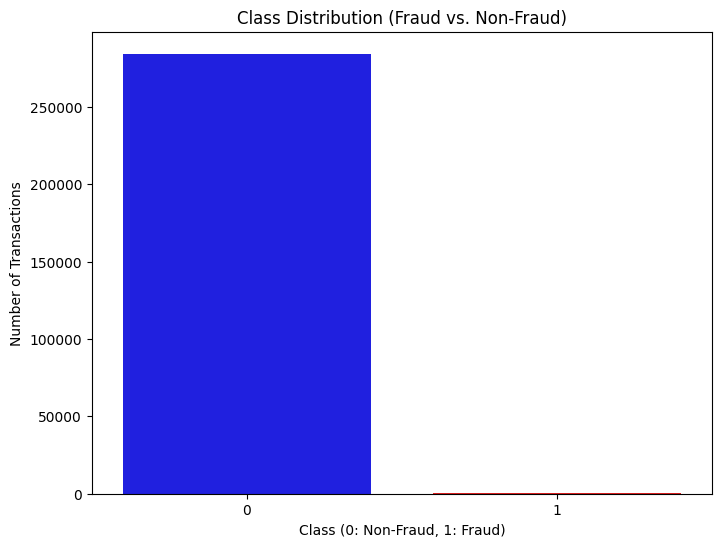

In [8]:
plt.figure(figsize=(8, 6))
sns.countplot(x='Class', data=cfd, hue='Class', palette=['blue', 'red'], legend=False)
plt.title('Class Distribution (Fraud vs. Non-Fraud)')
plt.xlabel('Class (0: Non-Fraud, 1: Fraud)')
plt.ylabel('Number of Transactions')
plt.show()

This code creates a count plot to visualize the distribution of fraudulent vs. non-fraudulent transactions.

**Class Distribution:**

**Non-Fraud**: 284,315 transactions

**Fraud**: 492 transactions

The dataset is highly imbalanced, with fraudulent transactions making up only 0.17% of the total transactions. This imbalance is typical in fraud detection datasets and poses a challenge for model training, as models may tend to predict the majority class (non-fraud) more frequently.

### **Distribution of Independent Variable**

**4.3 Distribution of Amount**

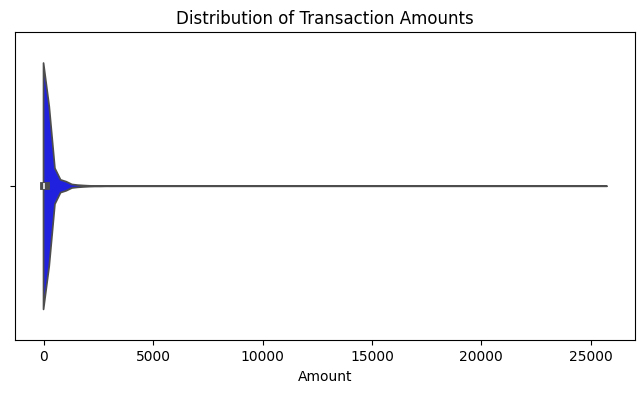

In [9]:
plt.figure(figsize=(8, 4))
sns.violinplot(x=cfd["Amount"], color="blue")
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Amount")
plt.show()

This code creates a violin plot to visualize the distribution of transaction amounts.

The majority of transactions are of low amounts, with a long tail of higher-value transactions.

This is expected, as most credit card transactions are small, and high-value transactions are less frequent.

The presence of outliers in the Amount feature suggests that some transactions are significantly larger than the rest.

**4.4 Distribution of Time**

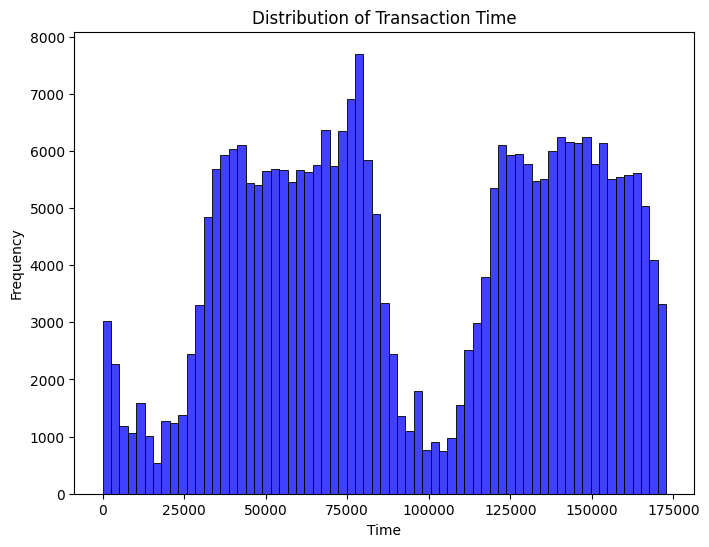

In [10]:
plt.figure(figsize=(8, 6))
sns.histplot(cfd['Time'], kde=False, color="blue")
plt.title('Distribution of Transaction Time')
plt.xlabel('Time')
plt.ylabel('Frequency')
plt.show()

This code creates a histogram to visualize the distribution of transaction times.

The Time feature represents the time elapsed since the first transaction in the dataset. The distribution appears to be uniform, with no obvious patterns or peaks, suggesting that transactions are evenly distributed over time.

**4.5 Histograms for Key Features (V1-V28, Amount, Time)**

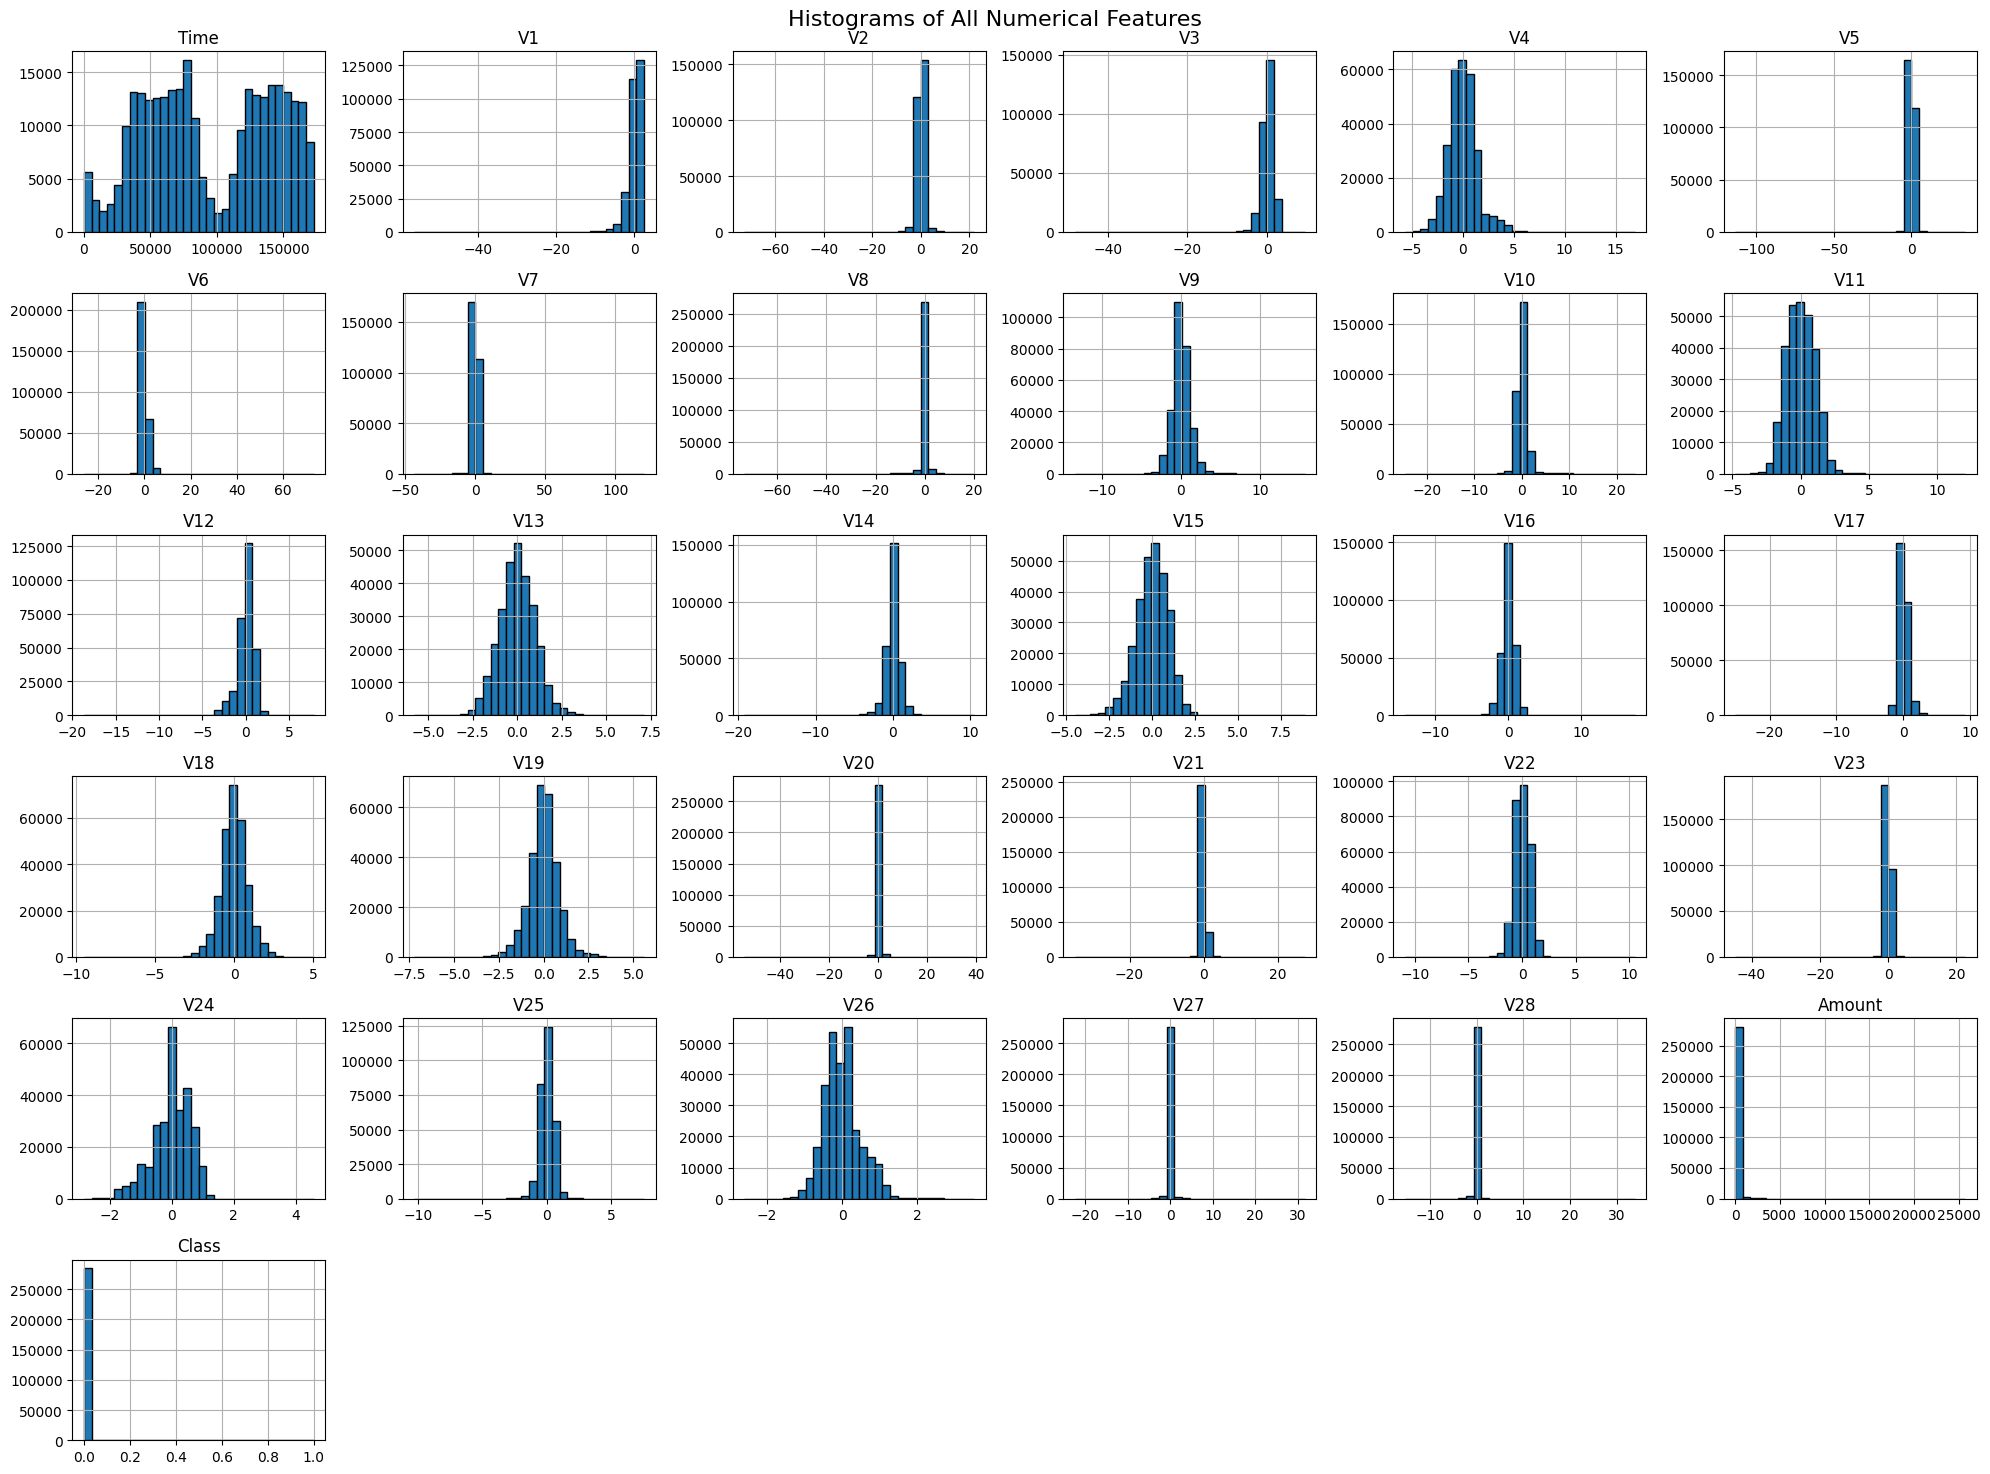

In [11]:
cfd.hist(bins=30, figsize=(20, 15), edgecolor='black')
plt.suptitle("Histograms of All Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

This code creates histograms for all numerical features in the dataset. Histograms for all numerical features (V1-V28, Amount, Time) are displayed.

The histograms show that most of the anonymized features (V1-V28) are centered around zero, with some features showing skewed distributions.

This is typical for PCA-transformed data, which is often used in fraud detection to anonymize sensitive information.

# **5. Pre-processing of Data**

**5.1 Checking of Null Values**

In [12]:
print("\nChecking for Null Values:")
cfd.isnull().sum()


Checking for Null Values:


,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


This code checks for null values in the dataset.

**5.2 Checking of Outliers**

In [13]:
Q1 = cfd['Amount'].quantile(0.25)
Q3 = cfd['Amount'].quantile(0.75)
IQR = Q3 - Q1

outliers = cfd[(cfd['Amount'] < (Q1 - 1.5 * IQR)) | (cfd['Amount'] > (Q3 + 1.5 * IQR))]
print(f"Number of outliers in 'Amount': {len(outliers)}")

Number of outliers in 'Amount': 31904


This code identifies outliers in the Amount column using the Interquartile Range (IQR) method.

**5.3 Checking of Duplicate Transactions**

In [14]:
cfd.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
284802,False
284803,False
284804,False
284805,False


This code checks for duplicate rows in the dataset.

In [15]:
duplicate_counts = cfd.duplicated().value_counts()
print(duplicate_counts)

False    283726
True       1081
Name: count, dtype: int64


This code counts the number of duplicate rows.

In [16]:
dup_mask = cfd.duplicated(keep="first")
n_dup = int(dup_mask.sum())
n_dup_fraud = int(cfd.loc[dup_mask, "Class"].sum())

print(f"Exact duplicate rows: {n_dup:,}")
print(f"  of which fraudulent: {n_dup_fraud}")
print(f"Dropping these removes {n_dup_fraud} fraud cases "
      f"({n_dup_fraud / cfd['Class'].sum():.1%} of the minority class).")

cfd = cfd.loc[~dup_mask].reset_index(drop=True)
print(f"\nRows after removal: {len(cfd):,} | fraud: {cfd['Class'].sum()}")

Exact duplicate rows: 1,081
  of which fraudulent: 19
Dropping these removes 19 fraud cases (3.9% of the minority class).

Rows after removal: 283,726 | fraud: 473


This code removes duplicate rows from the dataset.

**5.4 Feature Selection/Reduction**

**5.4.1 Correlation Matrix for Numerical Features**

In [17]:
correlation_matrix = cfd.corr()

This code calculates the correlation matrix for numerical features.

**5.4.2 Heatmap Visualization**

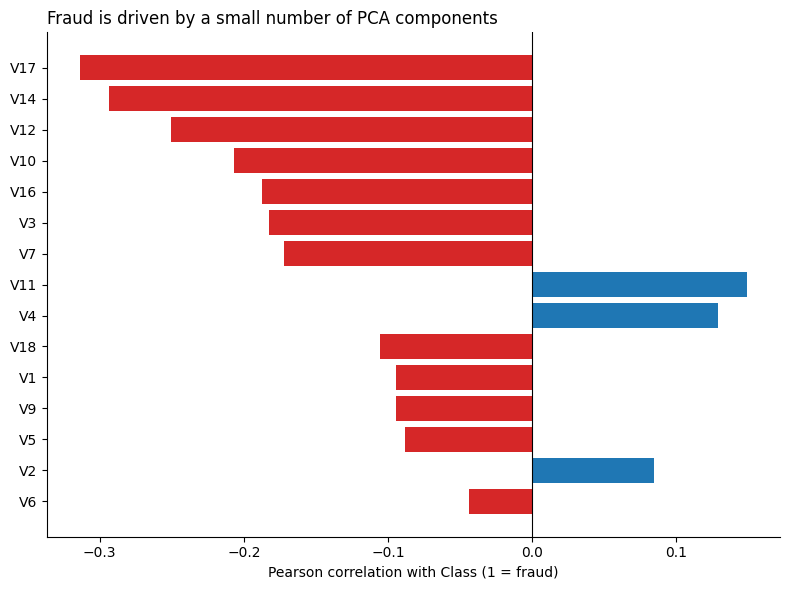

In [18]:
corr_with_target = cfd.corr(numeric_only=True)["Class"].drop("Class")
strong = corr_with_target.reindex(corr_with_target.abs().sort_values(ascending=False).index)[:15]

fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#d62728" if v < 0 else "#1f77b4" for v in strong.values]
ax.barh(strong.index[::-1], strong.values[::-1], color=colors[::-1])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Pearson correlation with Class (1 = fraud)")
ax.set_title("Fraud is driven by a small number of PCA components", loc="left")
sns.despine()
plt.tight_layout()
plt.show()

This code visualizes the correlation matrix as a heatmap.

The heatmap shows the correlation between different features.

Most features have low correlation with each other, which is expected since the features are PCA-transformed.

The Amount and Time features show some correlation with a few of the PCA features, but overall, the correlations are weak.

**5.4.3 Dropping Irrelevant Features**

In [19]:
threshold = 0.8
high_corr_features = set()
correlation_matrix = cfd.corr()

for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > threshold:
            colname = correlation_matrix.columns[i]
            high_corr_features.add(colname)

print("Highly correlated features to drop:", high_corr_features)

cfd = cfd.copy()
cfd.drop(columns=high_corr_features, inplace=True)
print(f"Updated dataset shape: {cfd.shape}")

Highly correlated features to drop: set()
Updated dataset shape: (283726, 31)


This code identifies and drops highly correlated features based on a threshold.

### **Application of Standard Scaler**

In [20]:
FEATURES = ["Time", "Amount"] + [f"V{i}" for i in range(1, 29)]

df = cfd.sort_values("Time", kind="mergesort").reset_index(drop=True)

cut = int(len(df) * 0.80)
train_df, test_df = df.iloc[:cut].copy(), df.iloc[cut:].copy()

X_train, y_train = train_df[FEATURES], train_df["Class"].astype(int)
X_test,  y_test  = test_df[FEATURES],  test_df["Class"].astype(int)

print(f"Train: {len(X_train):,} rows | fraud {y_train.sum()} ({y_train.mean():.4%})")
print(f"Test:  {len(X_test):,} rows | fraud {y_test.sum()} ({y_test.mean():.4%})")
print(f"Time boundary: train ends {train_df['Time'].max():.0f}, "
      f"test begins {test_df['Time'].min():.0f}")
print("\nTest set is a future window: no test transaction occurred before "
      "the last training transaction.")

Train: 226,980 rows | fraud 399 (0.1758%)
Test:  56,746 rows | fraud 74 (0.1304%)
Time boundary: train ends 145233, test begins 145234

Test set is a future window: no test transaction occurred before the last training transaction.


# **6. Machine Learning**

In [21]:
class AmountThresholdBaseline:
    """Flag a transaction when Amount exceeds a threshold fitted on train."""
    name = "Baseline: Amount > threshold"
    def __init__(self, target_recall=0.10):
        self.target_recall = target_recall
    def fit(self, X, y):
        pos = X.loc[y == 1, "Amount"]
        self.threshold_ = float(np.quantile(pos, 1 - self.target_recall))
        return self
    def score(self, X):
        return X["Amount"].to_numpy(dtype=float)
    def predict(self, X, threshold=None):
        return (self.score(X) > self.threshold_).astype(int)


class AlwaysLegitimate:
    """Predict 'not fraud' for everything. The floor every model must beat."""
    name = "Baseline: always legitimate"
    def fit(self, X, y): return self
    def score(self, X): return np.zeros(len(X))
    def predict(self, X, threshold=None): return np.zeros(len(X), dtype=int)


def precision_at_k(y_true, scores, k):
    k = min(k, len(scores))
    top = np.argsort(-scores, kind="mergesort")[:k]
    return float(np.mean(np.asarray(y_true)[top] == 1))


def evaluate_model(name, model, X_test, y_test, threshold=None):
    """Full evaluation. Scores (not labels) drive PR-AUC / ROC-AUC."""
    scores = model.score(X_test)
    preds = (scores >= threshold).astype(int) if threshold is not None \
        else model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(y_test, preds, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    f2 = 5 * precision * recall / (4 * precision + recall) if (4 * precision + recall) else 0.0

    return ({
        "Model": name,
        "Precision": precision, "Recall": recall, "F1": f1, "F2": f2,
        "PR_AUC": float(average_precision_score(y_test, scores)),
        "ROC_AUC": float(roc_auc_score(y_test, scores)),
        "Accuracy": float(np.mean(y_test == preds)),
        "Precision_at_0_1pct": precision_at_k(y_test, scores, max(1, int(0.001*len(scores)))),
        "Precision_at_1pct": precision_at_k(y_test, scores, int(0.01*len(scores))),
        "Alerts_per_10k": float(np.mean(preds == 1) * 10000),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
    }, scores, preds)


# Baselines run FIRST - a model is only interesting relative to these.
baseline_model = AmountThresholdBaseline().fit(X_train, y_train)
baseline_result, baseline_scores, baseline_preds = evaluate_model(
    "Baseline: Amount > threshold", baseline_model, X_test, y_test)

always_result, _, _ = evaluate_model(
    "Baseline: always legitimate", AlwaysLegitimate(), X_test, y_test)

print("BASELINE CHECK")
print(pd.Series(baseline_result).to_string())

BASELINE CHECK
Model                  Baseline: Amount > threshold
Precision                                  0.002347
Recall                                     0.081081
F1                                         0.004563
F2                                         0.010519
PR_AUC                                     0.001451
ROC_AUC                                    0.385075
Accuracy                                   0.953865
Precision_at_0_1pct                             0.0
Precision_at_1pct                          0.005291
Alerts_per_10k                           450.428224
TP                                                6
FP                                             2550
FN                                               68
TN                                            54122


### **Isolation Forest**

In [22]:
CONTAMINATION = float(y_train.mean())   # measured prior, not a guess

if_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", IsolationForest(
        n_estimators=300,
        contamination=CONTAMINATION,
        random_state=42, n_jobs=-1,
    )),
])
if_pipe.fit(X_train)

class IFDetector:
    name = "Isolation Forest"
    def score(self, X):
        return if_pipe["model"].decision_function(
            if_pipe["scale"].transform(X)) * -1
    def predict(self, X, threshold=None):
        t = -if_pipe["model"].offset_ if threshold is None else threshold
        return (self.score(X) >= t).astype(int)

if_model = IFDetector()
if_result, if_scores, if_preds = evaluate_model(
    "Isolation Forest", if_model, X_test, y_test)

print(pd.Series(if_result).to_string())

Model                  Isolation Forest
Precision                           0.0
Recall                              0.0
F1                                  0.0
F2                                  0.0
PR_AUC                         0.037511
ROC_AUC                        0.946951
Accuracy                       0.998696
Precision_at_0_1pct                 0.0
Precision_at_1pct              0.059965
Alerts_per_10k                      0.0
TP                                    0
FP                                    0
FN                                   74
TN                                56672


In [23]:
print(f"TP={if_result['TP']}  FP={if_result['FP']}  "
      f"FN={if_result['FN']}  TN={if_result['TN']}")

TP=0  FP=0  FN=74  TN=56672


### **Autoencoders**

In [24]:
class AutoencoderDetector:
    """Reconstruction-error anomaly detector.

    Trained on NORMAL transactions only, with a linear output layer, and
    thresholded at a calibrated operating point rather than an arbitrary
    percentile.
    """
    name = "Autoencoder"

    def __init__(self, latent=4, hidden=(32, 16), epochs=40,
                 batch_size=512, lr=1e-3, val_fraction=0.15):
        self.latent, self.hidden, self.epochs = latent, hidden, epochs
        self.batch_size, self.lr, self.val_fraction = batch_size, lr, val_fraction
        self.scaler = StandardScaler()
        self.model = None

    def _build(self, n_features):
        enc, prev = [], n_features
        for w in self.hidden:
            enc += [nn.Linear(prev, w), nn.ReLU()]
            prev = w
        bottleneck = nn.Linear(prev, self.latent)
        dec, prev = [], self.latent
        for w in reversed(self.hidden):
            dec += [nn.Linear(prev, w), nn.ReLU()]
            prev = w
        # LINEAR output, not sigmoid. Inputs are z-scored and roughly
        # half-negative; a sigmoid decoder cannot reconstruct them.
        out = nn.Linear(prev, n_features)
        return nn.Sequential(*enc, bottleneck, *dec, out)

    def fit(self, X, y):
        torch.manual_seed(42)

        # FIX 1: train on normal rows only. Training on fraud teaches the
        # network to reconstruct fraud, which defeats the entire purpose.
        normals = X.loc[np.asarray(y) == 0]
        self.scaler.fit(normals)
        Xs = self.scaler.transform(normals).astype(np.float32)

        rng = np.random.default_rng(42)
        perm = rng.permutation(len(Xs))
        n_val = int(len(Xs) * self.val_fraction)
        val_idx, tr_idx = perm[:n_val], perm[n_val:]
        Xtr = torch.tensor(Xs[tr_idx])
        Xva = torch.tensor(Xs[val_idx])

        self.model = self._build(Xs.shape[1])
        opt = torch.optim.Adam(self.model.parameters(), lr=self.lr, weight_decay=1e-5)
        lossf = nn.MSELoss()
        loader = DataLoader(TensorDataset(Xtr), batch_size=self.batch_size, shuffle=True)

        best, best_state, patience = np.inf, None, 0
        for _ in range(self.epochs):
            self.model.train()
            for (xb,) in loader:
                opt.zero_grad()
                lossf(self.model(xb), xb).backward()
                opt.step()
            self.model.eval()
            with torch.no_grad():
                v = float(lossf(self.model(Xva), Xva))
            if v < best - 1e-5:
                best, patience = v, 0
                best_state = {k: t.clone() for k, t in self.model.state_dict().items()}
            else:
                patience += 1
                if patience >= 6:
                    break

        if best_state is not None:
            self.model.load_state_dict(best_state)

        # FIX 2: calibrate the threshold on held-out validation normals.
        # The old np.percentile(mse, 80) flagged 20% of ALL transactions,
        # which is where the 11,264 false positives came from.
        val_errors = self.reconstruction_error(Xs[val_idx])
        self.threshold_ = float(np.quantile(val_errors, 1 - CONTAMINATION * 4))
        return self

    def reconstruction_error(self, X):
        Xs = self.scaler.transform(X).astype(np.float32)
        self.model.eval()
        with torch.no_grad():
            recon = self.model(torch.tensor(Xs)).numpy()
        return np.mean((Xs - recon) ** 2, axis=1)

    def score(self, X):
        return self.reconstruction_error(X)

    def predict(self, X, threshold=None):
        t = self.threshold_ if threshold is None else threshold
        return (self.score(X) >= t).astype(int)


ae_model = AutoencoderDetector().fit(X_train, y_train)
ae_result, ae_scores, ae_preds = evaluate_model(
    "Autoencoder", ae_model, X_test, y_test)

print(pd.Series(ae_result).to_string())

Model                  Autoencoder
Precision                 0.457627
Recall                    0.364865
F1                        0.406015
F2                        0.380282
PR_AUC                    0.298526
ROC_AUC                   0.937624
Accuracy                  0.998608
Precision_at_0_1pct       0.482143
Precision_at_1pct         0.097002
Alerts_per_10k           10.397209
TP                              27
FP                              32
FN                              47
TN                           56640


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


### **Local Outlier Factor**

In [25]:
lof_scaler = StandardScaler()
lof_fit = lof_scaler.fit(X_train.loc[y_train == 0]) # normals only

lof = LocalOutlierFactor(
    n_neighbors=50,
    contamination=CONTAMINATION,
    novelty=True, n_jobs=-1,
)
lof.fit(lof_fit.transform(X_train.loc[y_train == 0]))

class LOFDetector:
    name = "Local Outlier Factor"
    def score(self, X):
        return lof.decision_function(lof_scaler.transform(X)) * -1
    def predict(self, X, threshold=None):
        t = -lof.offset_ if threshold is None else threshold
        return (self.score(X) >= t).astype(int)

This code initializes and trains a Local Outlier Factor (LOF) model for outlier detection.

In [26]:
lof_model = LOFDetector()
lof_result, lof_scores, lof_preds = evaluate_model(
    "Local Outlier Factor", lof_model, X_test, y_test)

print(pd.Series(lof_result).to_string())

Model                  Local Outlier Factor
Precision                               0.0
Recall                                  0.0
F1                                      0.0
F2                                      0.0
PR_AUC                             0.015593
ROC_AUC                            0.872522
Accuracy                           0.998097
Precision_at_0_1pct                0.017857
Precision_at_1pct                  0.022928
Alerts_per_10k                     5.991612
TP                                        0
FP                                       34
FN                                       74
TN                                    56638


# **7. Evaluation of Model Performance**

**7.2 Selection of Best Performing Model**

,Precision,Recall,F1,F2,PR_AUC,ROC_AUC,Precision_at_0_1pct,Precision_at_1pct,Alerts_per_10k
Model,,,,,,,,,
Baseline: always legitimate,0.0000,0.0000,0.0000,0.0000,0.0013,0.5000,0.0000,0.0000,0.0000
Baseline: Amount > threshold,0.0023,0.0811,0.0046,0.0105,0.0015,0.3851,0.0000,0.0053,450.4282
Isolation Forest,0.0000,0.0000,0.0000,0.0000,0.0375,0.9470,0.0000,0.0600,0.0000
Autoencoder,0.4576,0.3649,0.4060,0.3803,0.2985,0.9376,0.4821,0.0970,10.3972
Local Outlier Factor,0.0000,0.0000,0.0000,0.0000,0.0156,0.8725,0.0179,0.0229,5.9916


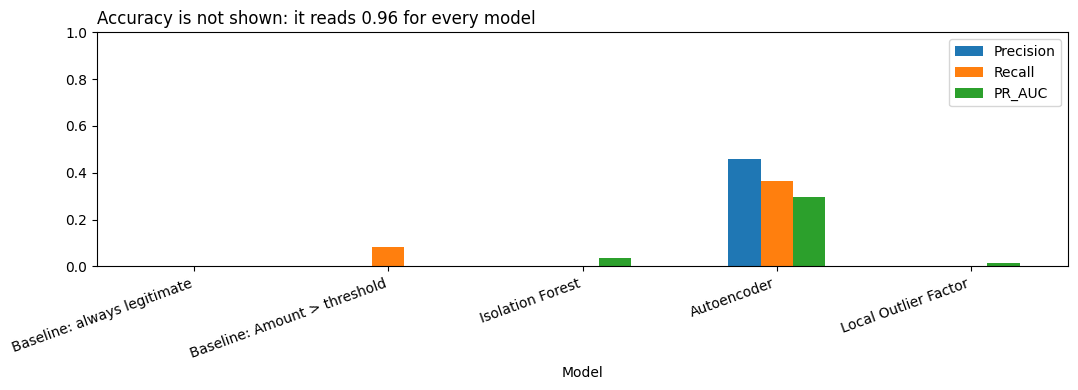

In [27]:
results_df = pd.DataFrame([
    always_result,
    baseline_result,
    if_result,
    ae_result,
    lof_result,
])

cols = ["Model", "Precision", "Recall", "F1", "F2", "PR_AUC", "ROC_AUC",
        "Precision_at_0_1pct", "Precision_at_1pct", "Alerts_per_10k"]
display(results_df[cols].set_index("Model").round(4))

ax = results_df.plot.bar(
    x="Model", y=["Precision", "Recall", "PR_AUC"], figsize=(11, 4),
    color=["#1f77b4", "#ff7f0e", "#2ca02c"], edgecolor="none")
ax.set_ylim(0, 1)
ax.set_title("Accuracy is not shown: it reads 0.96 for every model", loc="left")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**7.3 Feature Importance (Permutation)**

Instead of LIME, feature importance is measured by shuffling one feature at a
time and recording how much PR-AUC degrades. Unlike LIME's local surrogate,
this is measured on the actual fraud class and cannot produce a "probability"
that depends on the perturbation batch.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

Feature  Importance      Std
    V14    0.008036 0.000225
     V3    0.005959 0.000216
    V16    0.005425 0.000236
    V11    0.005411 0.000171
    V12    0.004535 0.000185
     V9    0.004089 0.000333
     V4    0.002814 0.000371
    V17    0.001917 0.000169
    V18    0.001716 0.000232
    V10    0.000961 0.000334


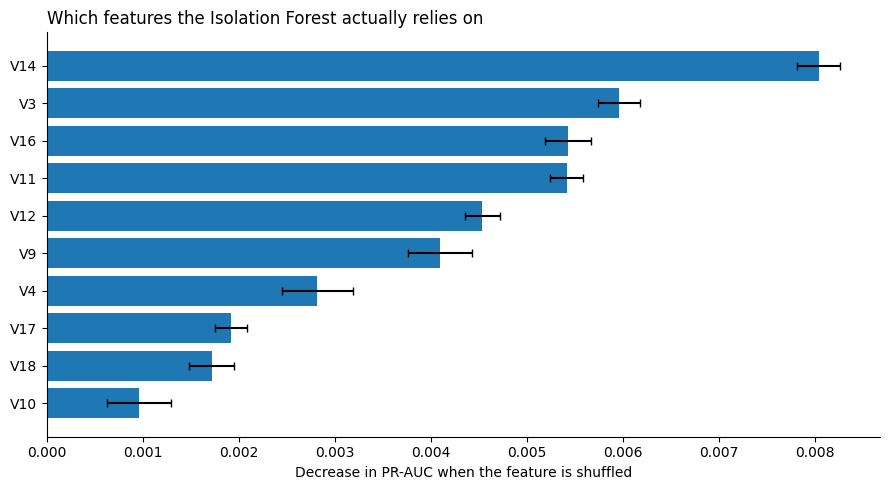

In [28]:
def permutation_importance_fraud(model, X, y, n_repeats=30, seed=42):
    """Custom permutation importance scored on PR-AUC (fraud class)."""
    rng = np.random.default_rng(seed)
    cols = list(X.columns)   # capture before converting
    X = np.asarray(X); y = np.asarray(y)
    base = average_precision_score(y, model.score(X))
    rows = []
    for j, col in enumerate(cols):
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[:, j] = rng.permutation(Xp[:, j])
            drops.append(base - average_precision_score(y, model.score(Xp)))
        rows.append((col, float(np.mean(drops)), float(np.std(drops))))
    return pd.DataFrame(rows, columns=["Feature", "Importance", "Std"]) \
             .sort_values("Importance", ascending=False)


imp = permutation_importance_fraud(if_model, X_test, y_test)
print(imp.head(10).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
top = imp.head(10).iloc[::-1]
ax.barh(top["Feature"], top["Importance"], xerr=top["Std"],
        color="#1f77b4", capsize=3)
ax.set_xlabel("Decrease in PR-AUC when the feature is shuffled")
ax.set_title("Which features the Isolation Forest actually relies on", loc="left")
sns.despine()
plt.tight_layout()
plt.show()

### **Statistical Tests**

In [29]:
def mcnemar_test(y_true, pred_a, pred_b):
    """Correct paired test for two classifiers on the same test set."""
    y_true = np.asarray(y_true); a = np.asarray(pred_a); b = np.asarray(pred_b)
    a_only = int(np.sum((a == y_true) & (b != y_true)))
    b_only = int(np.sum((a != y_true) & (b == y_true)))
    n = a_only + b_only
    if n == 0:
        return {"chi2": np.nan, "p": np.nan, "n_discordant": 0}
    chi2_stat = (abs(b_only - a_only) - 1) ** 2 / n
    return {"chi2": float(chi2_stat),
            "p": float(1 - chi2.cdf(chi2_stat, df=1)),
            "n_discordant": n,
            "a_only_correct": a_only, "other_only_correct": b_only}


def bootstrap_pr_auc_ci(y_true, scores, n_boot=2000, seed=42):
    """Percentile bootstrap CI. The test set holds ~100 fraud cases, so a
    bare point estimate overstates certainty."""
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true); scores = np.asarray(scores)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        vals.append(average_precision_score(y_true[idx], scores[idx]))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


for name, preds in [("Autoencoder", ae_preds), ("Local Outlier Factor", lof_preds)]:
    t = mcnemar_test(y_test, if_preds, preds)
    print(f"Isolation Forest vs {name}: chi2={t['chi2']:.2f}, "
          f"p={t['p']:.4f}, discordant={t['n_discordant']}")

lo, hi = bootstrap_pr_auc_ci(y_test, if_scores)
print(f"\nIsolation Forest PR-AUC: {if_result['PR_AUC']:.4f} "
      f"(95% CI {lo:.4f} - {hi:.4f})")

Isolation Forest vs Autoencoder: chi2=0.27, p=0.6025, discordant=59
Isolation Forest vs Local Outlier Factor: chi2=32.03, p=0.0000, discordant=34

Isolation Forest PR-AUC: 0.0375 (95% CI 0.0262 - 0.0531)


### **Cost Analysis**

In [30]:
COST_RATIO = 20   # stated assumption: a false positive costs 20x a false negative

print("Operational cost of the top-1% alert budget\n" + "=" * 46)
k = int(0.01 * len(y_test))
top = np.argsort(-if_scores, kind="mergesort")[:k]
tp = int((y_test.iloc[top] == 1).sum())
fp = k - tp
fn = int(y_test.sum()) - tp

print(f"Alerts raised        : {k:,}")
print(f"True fraud caught    : {tp}")
print(f"False alarms         : {fp:,}")
print(f"Fraud missed         : {fn}")
print(f"Ratio : {fp / tp:.1f} false alarms per true fraud")
print("-" * 46)
print(f"Cost at ratio {COST_RATIO:<4}   : {(fp * COST_RATIO + fn):,} units")
print(f"Cost of flagging none: {y_test.sum():,} units")
print(f"Reduction : "
      f"{(1 - (fp * COST_RATIO + fn) / y_test.sum()) * 100:.1f}%")

print("\nSensitivity to the cost assumption:")
for r in [1, 5, 10, 20, 50, 100]:
    print(f"  FP:FN = {r:>3}:x1  ->  {fp * r + fn:>10,} units")

Operational cost of the top-1% alert budget
Alerts raised        : 567
True fraud caught    : 34
False alarms         : 533
Fraud missed         : 40
Ratio : 15.7 false alarms per true fraud
----------------------------------------------
Cost at ratio 20     : 10,700 units
Cost of flagging none: 74 units
Reduction : -14359.5%

Sensitivity to the cost assumption:
  FP:FN =   1:x1  ->         573 units
  FP:FN =   5:x1  ->       2,705 units
  FP:FN =  10:x1  ->       5,370 units
  FP:FN =  20:x1  ->      10,700 units
  FP:FN =  50:x1  ->      26,690 units
  FP:FN = 100:x1  ->      53,340 units


### **Threshold Sweep**

In [31]:
def threshold_sweep(y_true, scores, model_name):
    y = np.asarray(y_true, dtype=int)
    order = np.argsort(-scores, kind="mergesort")
    y_sorted = (y[order] == 1).astype(int)
    rows = []
    for pct in [0.05, 0.1, 0.25, 0.5, 1, 2, 5]:
        k = max(1, int(pct / 100 * len(y)))
        tp = int(y_sorted[:k].sum())
        rows.append({
            "Model": model_name,
            "Alert rate %": pct,
            "Alerts": k,
            "Precision": tp / k,
            "Recall": tp / y.sum(),
        })
    return pd.DataFrame(rows)


sweep = pd.concat([
    threshold_sweep(y_test, if_scores, "Isolation Forest"),
    threshold_sweep(y_test, ae_scores, "Autoencoder"),
], ignore_index=True)
display(sweep.round(4))

,Model,Alert rate %,Alerts,Precision,Recall
0,Isolation Forest,0.05,28,0.0000,0.0000
1,Isolation Forest,0.10,56,0.0000,0.0000
2,Isolation Forest,0.25,141,0.0213,0.0405
3,Isolation Forest,0.50,283,0.0459,0.1757
4,Isolation Forest,1.00,567,0.0600,0.4595
5,Isolation Forest,2.00,1134,0.0388,0.5946
6,Isolation Forest,5.00,2837,0.0208,0.7973
7,Autoencoder,0.05,28,0.5000,0.1892
8,Autoencoder,0.10,56,0.4821,0.3649
9,Autoencoder,0.25,141,0.2766,0.5270


# **8. Detection of Fraud**

In [32]:
def predict_transaction(model, amount=5000.0, time_val=100000, **v):
    """Score a single transaction.

    Example:
        predict_transaction(if_model, Amount=5000, Time=100000)
    """
    row = pd.DataFrame([{
        "Time": time_val,
        "Amount": amount,
        **{f"V{i}": v.get(f"V{i}", 0.0) for i in range(1, 29)},
    }])[FEATURES]
    score = float(model.score(row)[0])
    verdict = "FRAUD" if score >= getattr(model, "threshold_", 0) else "LEGITIMATE"
    return verdict, score


for mdl in (if_model, ae_model, lof_model):
    print(f"{mdl.name:22} {predict_transaction(mdl)}")

Isolation Forest       ('LEGITIMATE', -0.27608793021629596)
Autoencoder            ('FRAUD', 8.257697105407715)
Local Outlier Factor   ('LEGITIMATE', -0.02004911670670806)
